In [71]:
import numpy as np
import cv2
from cv2 import aruco
import rospkg, ros_numpy
import os
from hil_common import utils
from scipy.spatial.transform import Rotation as R
import matplotlib.pyplot as plt 
from mpl_toolkits.mplot3d import Axes3D
from scipy.spatial.transform import Rotation as rot

rospack = rospkg.RosPack()
fileDir = os.path.join(rospack.get_path('hil'), 'experimentation', 'calib_data')
iter = 1
img_path = os.path.join(fileDir, 'img', f'im_{iter}.jpg')
pc_path = os.path.join(fileDir, 'pc', f'pc_{iter}.npy')
calib_path = os.path.join(fileDir, 'camera_info.npz')

img = cv2.imread(img_path)
pc = np.load(pc_path)
calib = np.load(calib_path)
P = calib['P']
D = calib['D']
print(P, D)

desired_ids = [5, 11]
long_edge = 61.4
short_edge = 42.2
long_paper = 29.7
short_paper = 21.0
paper_down_margin = 7.6
paper_left_margin = 3.25 # Technically 3.25
marker_length = 14.5
m_by2 = marker_length/2
del_long_edge = long_edge - long_paper + 2
del_short_edge = short_edge - short_paper

# Order is left, up, right, down
cardboard_pts = np.array([ 
    [-(m_by2+paper_down_margin), m_by2+paper_left_margin, 0],
    [+(m_by2+paper_down_margin+del_long_edge), m_by2+paper_left_margin, 0],
    [+(m_by2+paper_down_margin+del_long_edge), -(m_by2+paper_left_margin+del_short_edge), 0],
    [-(m_by2+paper_down_margin), -(m_by2+paper_left_margin+del_short_edge), 0]
])
# cardboard_pts = np.append(cardboard_pts, [cardboard_pts[0]+[long_edge,0, 0]], axis=0)
# cardboard_pts =  np.append(cardboard_pts, [cardboard_pts[0]+[long_edge,short_edge, 0]], axis=0)
# cardboard_pts =  np.append(cardboard_pts, [cardboard_pts[0]+[0,short_edge, 0]], axis=0)
print(cardboard_pts)

base_T_depth_rgb = np.array([
    [0, -1, 0, 0],
    [0, 0, -1, 0],
    [1, 0, 0, 0],
    [0, 0, 0, 1]
])

[[527.56256104   0.         616.24493408   0.        ]
 [  0.         527.56256104 359.1973877    0.        ]
 [  0.           0.           1.           0.        ]] [0. 0. 0. 0. 0.]
[[-14.85  10.5    0.  ]
 [ 48.55  10.5    0.  ]
 [ 48.55 -31.7    0.  ]
 [-14.85 -31.7    0.  ]]


### Finding image cardboard points

In [72]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
aruco_dict = aruco.Dictionary_get(aruco.DICT_ARUCO_ORIGINAL)
parameters =  aruco.DetectorParameters_create()
corners, ids, rejectedImgPoints = aruco.detectMarkers(gray, aruco_dict, parameters=parameters)
# Filter aruco markers by id
valid_inds = [i for i in range(len(ids)) if ids[i] in desired_ids]
corners = [corners[i] for i in valid_inds]
print(corners)
ids = np.array([ids[i] for i in valid_inds])
result_image = img.copy()
cam_pts = []
if len(ids) > 0:
    rvecs, tvecs, _ = aruco.estimatePoseSingleMarkers(
                        corners, 
                        marker_length, 
                        P[:3,:3], 
                        (0,0,0,0,0)
                    )
    # uv_pts = utils.applyTransform(cam_pts, P).T
    # uv_pts[:2, :] /= uv_pts[2, :]
    for i in range(len(rvecs)-1,-1,-1):
        rvec = rvecs[i][0]
        tvec = tvecs[i][0]
        T_marker_camera = np.eye(4)
        T_marker_camera[:3,:3] = R.from_rotvec(rvec).as_matrix()
        T_marker_camera[:3, 3] = tvec
        # print(rvec, tvec)
        cam_pts.append(utils.applyTransform(cardboard_pts, T_marker_camera))

        uv_pts = utils.applyTransform(cardboard_pts, P @ T_marker_camera).T
        uv_pts[:2, :] /= uv_pts[2, :]
        # print(uv_pts)
        for i in range(len(uv_pts[0])):
            cv2.drawMarker(result_image, tuple(uv_pts[:2, i].astype(int)), color=(0,255,0), markerType=cv2.MARKER_CROSS, thickness=1)
        result_image = aruco.drawAxis(
                        result_image, 
                        P[:3,:3], 
                        D,
                        rvec, tvec, marker_length)
        
# Draw axes and bounds on image
result_image = aruco.drawDetectedMarkers(result_image, corners, ids)
print(cam_pts)
cam_pts[0] = np.roll(cam_pts[0], -1, 0)
cam_pts[1] = np.roll(cam_pts[1], -1, 0)

cam_pts = np.array(cam_pts).reshape(8,3)/100
print("cam_pts", cam_pts)
np.save('cam_pts.npy', cam_pts)
cv2.imshow("Final Image window", result_image)
cv2.waitKey(0)
cv2.destroyAllWindows()

[array([[[919., 351.],
        [955., 323.],
        [986., 355.],
        [948., 381.]]], dtype=float32), array([[[567., 322.],
        [586., 297.],
        [611., 316.],
        [593., 341.]]], dtype=float32)]
[array([[-29.20316861, -12.72224482, 237.57951239],
       [  7.12840515, -63.5135733 , 248.52563951],
       [ 40.85440446, -38.49207141, 252.6875398 ],
       [  4.5228307 ,  12.29925707, 241.74141268]]), array([[100.65662167,  -0.55783452, 191.25746046],
       [144.03226083, -41.62995916, 170.01612095],
       [171.54509085, -10.01629193, 165.07039264],
       [128.16945168,  31.05583272, 186.31173215]])]
cam_pts [[ 0.07128405 -0.63513573  2.4852564 ]
 [ 0.40854404 -0.38492071  2.5268754 ]
 [ 0.04522831  0.12299257  2.41741413]
 [-0.29203169 -0.12722245  2.37579512]
 [ 1.44032261 -0.41629959  1.70016121]
 [ 1.71545091 -0.10016292  1.65070393]
 [ 1.28169452  0.31055833  1.86311732]
 [ 1.00656622 -0.00557835  1.9125746 ]]


In [54]:
lidar_pts = []
with open('/home/bhargav/catkin_ws/src/HIL_Research/hil/experimentation/aruco_testing/points.txt') as f:
    content = f.read().splitlines()
    n = int(content[0])
    for i in range(1,n+1):
        lidar_pts.append([float(i) for i in content[i].split()])
    for i in range(n+1, 2*n+1):
        cam_pts.append([float(i) for i in content[i].split()])
lidar_pts = np.array(lidar_pts)
cam_pts = np.array(cam_pts)
# T_depth_rgb = utils.fit_rigid(lidar_pts.T, cam_pts.T)
cam_pts[:, 0] -= 0.1
num_pts = cam_pts.shape[0]
uv_pts = utils.applyTransform(cam_pts, P).T
uv_pts[:2, :] /= uv_pts[2, :]
lidar_uv_pts = utils.applyTransform(lidar_pts, P@T_depth_rgb).T
lidar_uv_pts[:2, :] /= lidar_uv_pts[2, :]

# plt.scatter(x=lidar_uv_pts[0], y=lidar_uv_pts[1], c='b', s=40, label="Lidar")

# plt.scatter(x=uv_pts[0], y=uv_pts[1], c='r', s=40, label="Camera")
# plt.legend()
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(lidar_pts[:,0], lidar_pts[:,1], lidar_pts[:,2], label='lidar')
ax.scatter(cam_pts[:,0], cam_pts[:,1], cam_pts[:,2], label='camera')
ax.legend()
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
plt.show()

In [22]:
print(pc['ring'])

for ringNum in range(0,15):
    inds = np.where(pc['ring'] == i)
    

[ 0  8  1 ... 14  7 15]


AttributeError: module 'numpy.lib' has no attribute 'recfunctions'

('x', 'y', 'z', 'intensity', 'ring')


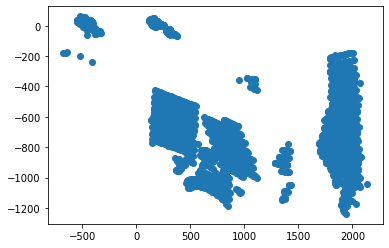

In [26]:
intensity_thresh = 10000
radius = 2.5
inds = np.where((pc['intensity'] < intensity_thresh) & (pc['x'] < radius) & (pc['y'] < radius)
                & (pc['x'] > -radius) & (pc['y'] > -radius))
filtered_pc = pc[inds]
pts_depth = ros_numpy.point_cloud2.get_xyz_points(filtered_pc, remove_nans=True) # (3,n) shape
pts_depth = utils.applyTransform(pts_depth, base_T_depth_rgb)
# print(pts_depth)

# pts_2d, depths = utils.project_to_image(pts_depth, P, base_T_depth_rgb)

# Filter lidar points to be within image FOV
# inds = np.where((pts_2d[0, :] < img.shape[1]) & (pts_2d[0, :] >= 0) &
#                 (pts_2d[1, :] < img.shape[0]) & (pts_2d[1, :] >= 0) 
#                 & (depths > 0)
#                 )[0]
# print(inds.shape)
# # Filter out pixels points
# imgfov_pc_pixel = pts_2d[:, inds]
# imgfov_pc_depth = depths[inds]
print(pc.dtype.names)
filtered_pc = pc[inds]
plt.scatter(pts_depth[:,0], -pts_depth[:,1])
plt.show()

In [ ]:
import pcardext